# Vision Transformer: learning from image patches

    Lab 2 · MNIST · PyTorch · Google Colab T4

    **Goal.** Implement patch tokenization, attention, residual encoder blocks and fixed sinusoidal positions without loading a pretrained Transformer.

    

## 1. Configuration and Drive storage

    One seeded run, one GPU. Seeds and deterministic cuDNN settings improve repeatability; bitwise equality across software and hardware versions is not guaranteed. Record package versions with the results.


In [1]:
MODEL_KEY = 'vit'
CONFIG = {'input_size': 28, 'channels': 1, 'mean': [0.1307], 'std': [0.3081], 'batch_size': 128, 'max_epochs': 30, 'patience': 5, 'optimizer': 'AdamW', 'learning_rate': 0.0003, 'weight_decay': 0.01, 'augmentation': {'rotation_degrees': 8, 'translation_fraction': 0.05}, 'architecture': 'manual ViT: patch-linear-cls-sinusoidal-4encoders-layernorm-linear10', 'dropout': 0.1, 'patch_size': 4, 'embedding_dim': 64, 'depth': 4, 'heads': 4, 'mlp_ratio': 4, 'positional_encoding': 'fixed sinusoidal'}

from pathlib import Path
import copy, csv, hashlib, json, math, os, platform, random, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from tqdm.auto import tqdm

if not torch.cuda.is_available():
    raise RuntimeError('Select Runtime > Change runtime type > T4 GPU, then reconnect.')
DEVICE = torch.device('cuda:0')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

from google.colab import drive
drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/Atelier2_MNIST')
RUN_DIR = PROJECT / 'runs' / MODEL_KEY
RUN_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_DATA = Path('/content/mnist_data')
CONFIG['seed'] = SEED
CONFIG['gpu_name'] = torch.cuda.get_device_name(0)
CONFIG['gpu_count_used'] = 1
CONFIG['torch_version'] = str(torch.__version__)
CONFIG['torchvision_version'] = str(torchvision.__version__)
CONFIG['python_version'] = platform.python_version()
print('GPU:', CONFIG['gpu_name'])
print('Outputs:', RUN_DIR)

def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False))
    os.replace(temporary, path)

def atomic_torch_save(value, path):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    torch.save(value, temporary)
    os.replace(temporary, path)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_loader(dataset, batch_size, shuffle=False, collate_fn=None):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, num_workers=2,
        pin_memory=True, worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(SEED), collate_fn=collate_fn,
    )

def split_digest(train_indices, validation_indices):
    payload = json.dumps({'train': train_indices, 'validation': validation_indices}, separators=(',', ':'))
    return hashlib.sha256(payload.encode()).hexdigest()


Mounted at /content/drive
GPU: Tesla T4
Outputs: /content/drive/MyDrive/Atelier2_MNIST/runs/vit


## Download the required MNIST dataset from Kaggle

    The source is exclusively [hojjatk/mnist-dataset](https://www.kaggle.com/datasets/hojjatk/mnist-dataset), as specified by the lab. `kagglehub` downloads its latest version to the Colab runtime cache. Search for the four IDX files, decompress `.gz` files if needed, and verify magic numbers, image dimensions, counts and file lengths. Save file fingerprints in Drive so the exact data can be checked across runs. There is no fallback to another MNIST download source.


In [2]:
# Kaggle is the only MNIST download source. Torchvision will read local IDX files.
import gzip
import importlib.metadata
import shutil
import struct
import subprocess
import sys
try:
    import kagglehub
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', 'kagglehub'])
    import kagglehub

DATASET_HANDLE = 'hojjatk/mnist-dataset'
path = kagglehub.dataset_download(DATASET_HANDLE)
print('Path to dataset files:', path)
dataset_path = Path(path)
raw_directory = LOCAL_DATA / 'MNIST' / 'raw'
raw_directory.mkdir(parents=True, exist_ok=True)

def validate_idx_file(file_path, magic, expected_count):
    # Validate the decompressed IDX header and exact payload size before loading.
    with Path(file_path).open('rb') as file:
        header = file.read(8)
        if len(header) != 8:
            raise ValueError(f'Truncated IDX header: {file_path}')
        actual_magic, count = struct.unpack('>II', header)
        if actual_magic != magic or count != expected_count:
            raise ValueError(f'Unexpected IDX magic/count in {file_path}: {actual_magic}, {count}')
        if magic == 2051:
            dimensions = file.read(8)
            if len(dimensions) != 8 or struct.unpack('>II', dimensions) != (28, 28):
                raise ValueError(f'Expected 28x28 images: {file_path}')
            expected_bytes = 16 + count * 28 * 28
        else:
            labels = file.read()
            if len(labels) != count or any(label > 9 for label in labels):
                raise ValueError(f'Invalid digit labels: {file_path}')
            expected_bytes = 8 + count
    if Path(file_path).stat().st_size != expected_bytes:
        raise ValueError(f'IDX payload length mismatch: {file_path}')

def stage_idx_file(source_root, destination_root, filename, magic, count):
    candidates = sorted(
        (p for p in Path(source_root).rglob('*') if p.is_file() and p.name in (filename, filename + '.gz')),
        key=lambda p: (p.suffix == '.gz', str(p)),
    )
    if not candidates:
        raise FileNotFoundError(f'{filename} or {filename}.gz not found in Kaggle dataset {source_root}')
    source = candidates[0]
    destination = Path(destination_root) / filename
    temporary = destination.with_suffix(destination.suffix + '.tmp')
    try:
        opener = gzip.open if source.name.endswith('.gz') else open
        with opener(source, 'rb') as incoming, temporary.open('wb') as outgoing:
            shutil.copyfileobj(incoming, outgoing)
        validate_idx_file(temporary, magic, count)
        os.replace(temporary, destination)
    finally:
        temporary.unlink(missing_ok=True)
    digest = hashlib.sha256()
    with destination.open('rb') as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(chunk)
    print('Kaggle IDX ready:', filename)
    return digest.hexdigest()

required_files = {
    'train-images-idx3-ubyte': (2051, 60000),
    'train-labels-idx1-ubyte': (2049, 60000),
    't10k-images-idx3-ubyte': (2051, 10000),
    't10k-labels-idx1-ubyte': (2049, 10000),
}
dataset_hashes = {
    filename: stage_idx_file(dataset_path, raw_directory, filename, magic, count)
    for filename, (magic, count) in required_files.items()
}
CONFIG['dataset_handle'] = DATASET_HANDLE
CONFIG['dataset_file_sha256'] = dataset_hashes
CONFIG['kagglehub_version'] = importlib.metadata.version('kagglehub')
write_json(RUN_DIR / 'dataset_provenance.json', {
    'handle': DATASET_HANDLE, 'download_path': str(dataset_path),
    'file_sha256': dataset_hashes, 'kagglehub_version': CONFIG['kagglehub_version'],
})


Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset
Kaggle IDX ready: train-images-idx3-ubyte
Kaggle IDX ready: train-labels-idx1-ubyte
Kaggle IDX ready: t10k-images-idx3-ubyte
Kaggle IDX ready: t10k-labels-idx1-ubyte


## 2. Shared data protocol

    Use 54,000 training images, 6,000 validation images and the untouched official 10,000-image test set. All four new notebooks share exactly the same split indices. Training augmentation applies rotation up to ±8° and translation up to 5%; validation and test have no random augmentation. Three-channel models repeat the grayscale image and use ImageNet normalization; one-channel models use MNIST normalization.


Train 54000 | validation 6000 | test 10000


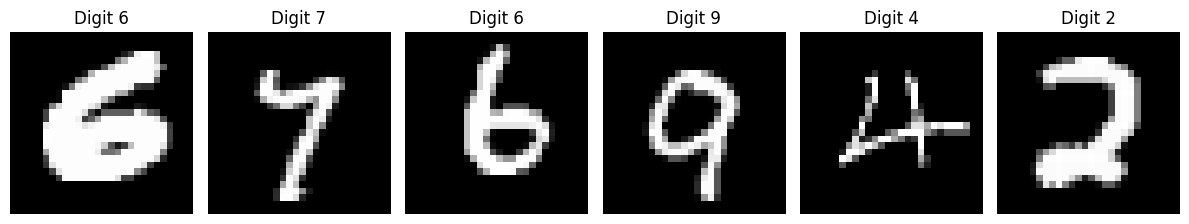

In [3]:
# The same seeded index assignment is regenerated and checked in all four notebooks.
permutation = torch.randperm(60000, generator=torch.Generator().manual_seed(SEED)).tolist()
validation_indices = permutation[:6000]
train_indices = permutation[6000:]
split = {'seed': SEED, 'train_indices': train_indices, 'validation_indices': validation_indices,
         'test': 'official MNIST test split; all 10000 images'}
split_path = PROJECT / 'shared_split.json'
if split_path.exists():
    if json.loads(split_path.read_text()) != split:
        raise RuntimeError('Existing Drive split differs. Use a new project folder rather than overwrite it.')
else:
    write_json(split_path, split)
assert len(set(train_indices) & set(validation_indices)) == 0
assert len(set(train_indices + validation_indices)) == 60000
CONFIG['split_sha256'] = split_digest(train_indices, validation_indices)
CONFIG['train_size'], CONFIG['validation_size'], CONFIG['test_size'] = 54000, 6000, 10000

def image_transform(training=False):
    steps = []
    if training:
        steps.append(transforms.RandomAffine(degrees=8, translate=(0.05, 0.05), fill=0))
    if CONFIG['input_size'] != 28:
        steps.append(transforms.Resize((CONFIG['input_size'], CONFIG['input_size']), antialias=True))
    if CONFIG['channels'] == 3:
        steps.append(transforms.Grayscale(num_output_channels=3))
    steps.extend([transforms.ToTensor(), transforms.Normalize(CONFIG['mean'], CONFIG['std'])])
    return transforms.Compose(steps)

training_source = datasets.MNIST(LOCAL_DATA, train=True, download=False, transform=image_transform(True))
validation_source = datasets.MNIST(LOCAL_DATA, train=True, download=False, transform=image_transform(False))
test_set = datasets.MNIST(LOCAL_DATA, train=False, download=False, transform=image_transform(False))
train_set = Subset(training_source, train_indices)
validation_set = Subset(validation_source, validation_indices)
train_loader = make_loader(train_set, CONFIG['batch_size'], shuffle=True)
validation_loader = make_loader(validation_set, CONFIG['batch_size'])
test_loader = make_loader(test_set, CONFIG['batch_size'])
write_json(RUN_DIR / 'config.json', CONFIG)
print(f'Train {len(train_set)} | validation {len(validation_set)} | test {len(test_set)}')

images, labels = next(iter(validation_loader))
assert images.shape[1:] == (CONFIG['channels'], CONFIG['input_size'], CONFIG['input_size'])
mean = torch.tensor(CONFIG['mean']).view(-1, 1, 1)
std = torch.tensor(CONFIG['std']).view(-1, 1, 1)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, image, label in zip(axes, images[:6], labels[:6]):
    display = (image * std + mean).clamp(0, 1)
    ax.imshow(display[0] if CONFIG['channels'] == 1 else display.permute(1, 2, 0), cmap='gray')
    ax.set_title(f'Digit {label.item()}'); ax.axis('off')
plt.tight_layout(); plt.show()


## 3. Model and optimizer

    Inspect the architecture and parameter counts before training. A shape check below uses validation images only. Learning rates for pretrained layers are smaller than those for newly initialized classifiers.


In [4]:
def sinusoidal_positions(length, dimension):
    assert dimension % 2 == 0
    positions = torch.arange(length, dtype=torch.float32).unsqueeze(1)
    frequencies = torch.exp(torch.arange(0, dimension, 2, dtype=torch.float32) * (-math.log(10000.0) / dimension))
    encoding = torch.zeros(1, length, dimension)
    encoding[0, :, 0::2] = torch.sin(positions * frequencies)
    encoding[0, :, 1::2] = torch.cos(positions * frequencies)
    return encoding

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, dimension, heads, dropout):
        super().__init__()
        assert dimension % heads == 0
        self.heads, self.head_dimension = heads, dimension // heads
        self.qkv = nn.Linear(dimension, 3 * dimension)
        self.attention_dropout = nn.Dropout(dropout)
        self.output = nn.Sequential(nn.Linear(dimension, dimension), nn.Dropout(dropout))
    def forward(self, tokens):
        batch, length, dimension = tokens.shape
        qkv = self.qkv(tokens).reshape(batch, length, 3, self.heads, self.head_dimension)
        query, key, value = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        scores = (query @ key.transpose(-2, -1)) / math.sqrt(self.head_dimension)
        attention = self.attention_dropout(scores.softmax(dim=-1))
        combined = (attention @ value).transpose(1, 2).reshape(batch, length, dimension)
        return self.output(combined)

class EncoderBlock(nn.Module):
    def __init__(self, dimension, heads, dropout, mlp_ratio=4):
        super().__init__()
        self.attention_norm = nn.LayerNorm(dimension)
        self.attention = MultiHeadSelfAttention(dimension, heads, dropout)
        self.mlp_norm = nn.LayerNorm(dimension)
        self.mlp = nn.Sequential(nn.Linear(dimension, dimension * mlp_ratio), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(dimension * mlp_ratio, dimension), nn.Dropout(dropout))
    def forward(self, tokens):
        tokens = tokens + self.attention(self.attention_norm(tokens))
        return tokens + self.mlp(self.mlp_norm(tokens))

class DigitVisionTransformer(nn.Module):
    def __init__(self, patch_size=4, dimension=64, depth=4, heads=4, dropout=0.1, mlp_ratio=4):
        super().__init__()
        assert 28 % patch_size == 0
        self.patch_size = patch_size
        self.patch_projection = nn.Linear(patch_size * patch_size, dimension)
        self.class_token = nn.Parameter(torch.zeros(1, 1, dimension))
        self.register_buffer('positions', sinusoidal_positions((28 // patch_size)**2 + 1, dimension))
        self.embedding_dropout = nn.Dropout(dropout)
        self.blocks = nn.Sequential(*[EncoderBlock(dimension, heads, dropout, mlp_ratio) for _ in range(depth)])
        self.head = nn.Sequential(nn.LayerNorm(dimension), nn.Linear(dimension, 10))
        nn.init.normal_(self.class_token, std=0.02)
    def forward(self, images):
        batch, channels, height, width = images.shape
        assert (channels, height, width) == (1, 28, 28)
        p = self.patch_size
        patches = images.unfold(2, p, p).unfold(3, p, p)
        patches = patches.permute(0, 2, 3, 1, 4, 5).reshape(batch, (28 // p)**2, p*p)
        tokens = self.patch_projection(patches)
        tokens = torch.cat([self.class_token.expand(batch, -1, -1), tokens], dim=1)
        tokens = self.embedding_dropout(tokens + self.positions)
        return self.head(self.blocks(tokens)[:, 0])

model = DigitVisionTransformer(patch_size=CONFIG['patch_size'], dimension=CONFIG['embedding_dim'],
                              depth=CONFIG['depth'], heads=CONFIG['heads'], dropout=CONFIG['dropout'],
                              mlp_ratio=CONFIG['mlp_ratio']).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=CONFIG['weight_decay'])


model = model.to(DEVICE)
model.eval()
with torch.inference_mode():
    shape = model(images[:2].to(DEVICE)).shape
assert tuple(shape) == (2, 10), shape
print(model)
print('Total parameters:', sum(p.numel() for p in model.parameters()))
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


DigitVisionTransformer(
  (patch_projection): Linear(in_features=16, out_features=64, bias=True)
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (blocks): Sequential(
    (0): EncoderBlock(
      (attention_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attention): MultiHeadSelfAttention(
        (qkv): Linear(in_features=64, out_features=192, bias=True)
        (attention_dropout): Dropout(p=0.1, inplace=False)
        (output): Sequential(
          (0): Linear(in_features=64, out_features=64, bias=True)
          (1): Dropout(p=0.1, inplace=False)
        )
      )
      (mlp_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (mlp): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): GELU(approximate='none')
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=256, out_features=64, bias=True)
        (4): Dropout(p=0.1, inplace=False)
      )
    )
    (1): EncoderBlock(
      (atte

## 4. Train and select on validation

    Cross-entropy receives raw logits. Loss is averaged by the number of images, not by the number of batches. Validation selects checkpoints and controls the scheduler and early stopping; the test loader is not used here.

    Timing includes training, validation and best-checkpoint writes to Drive, but excludes downloads, setup and final test evaluation. The first epoch gives a hardware-specific estimate. Stop once the patience limit is reached and restore the lowest-validation-loss model.


In [5]:
criterion = nn.CrossEntropyLoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
BEST_PATH = RUN_DIR / 'best_checkpoint.pt'

def classification_epoch(loader, training=False):
    model.train(training)
    loss_sum, correct, samples = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in tqdm(loader, leave=False, desc='Train' if training else 'Validation'):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            loss_sum += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            samples += len(labels)
    return loss_sum / samples, correct / samples

# Prevent accidental replacement of a completed experiment. Change this explicitly for a fresh run.
OVERWRITE_RUN = False
if (RUN_DIR / 'history.json').exists() and not OVERWRITE_RUN:
    raise RuntimeError('This run already has a history. Load its checkpoint for evaluation, or explicitly enable OVERWRITE_RUN.')
# If explicitly restarting, do not let previous metrics survive a new or interrupted training run.
for stale_file in ['metrics.json', 'predictions.csv', 'test_evaluation_started.json']:
    (RUN_DIR / stale_file).unlink(missing_ok=True)

best_loss, best_epoch, stale_epochs = float('inf'), None, 0
history = []
training_seconds = 0.0
for epoch in range(1, CONFIG['max_epochs'] + 1):
    torch.cuda.synchronize()
    start = time.perf_counter()
    train_loss, train_accuracy = classification_epoch(train_loader, training=True)
    validation_loss, validation_accuracy = classification_epoch(validation_loader)
    scheduler.step(validation_loss)
    improved = validation_loss < best_loss
    if improved:
        best_loss, best_epoch, stale_epochs = validation_loss, epoch, 0
        atomic_torch_save({'model_state': model.state_dict(), 'epoch': epoch,
                          'validation_loss': validation_loss, 'config': CONFIG}, BEST_PATH)
    else:
        stale_epochs += 1
    torch.cuda.synchronize()
    epoch_seconds = time.perf_counter() - start
    training_seconds += epoch_seconds
    history.append({'epoch': epoch, 'train_loss': train_loss, 'train_accuracy': train_accuracy,
                    'validation_loss': validation_loss, 'validation_accuracy': validation_accuracy,
                    'epoch_seconds': epoch_seconds, 'training_seconds': training_seconds,
                    'learning_rates': [g['lr'] for g in optimizer.param_groups], 'best_epoch': best_epoch})
    write_json(RUN_DIR / 'history.json', history)
    print(f'Epoch {epoch:02d}: train loss {train_loss:.4f}, val loss {validation_loss:.4f}, '
          f'val accuracy {validation_accuracy:.2%}, time {epoch_seconds:.1f}s')
    if epoch == 1:
        print(f'First-epoch estimate for {CONFIG["max_epochs"]} epochs: '
              f'{epoch_seconds * CONFIG["max_epochs"] / 60:.1f} min; early stopping may shorten it.')
    if stale_epochs >= CONFIG['patience']:
        print('Early stopping.'); break

checkpoint = torch.load(BEST_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state'])
model.eval()
print(f'Best epoch: {checkpoint["epoch"]}; total training/validation/checkpoint time: {training_seconds / 60:.2f} min')


Train:   0%|          | 0/422 [00:00<?, ?it/s]

Validation:   0%|          | 0/47 [00:00<?, ?it/s]

Epoch 01: train loss 1.5491, val loss 0.6421, val accuracy 78.87%, time 25.1s
First-epoch estimate for 30 epochs: 12.5 min; early stopping may shorten it.


Train:   0%|          | 0/422 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>    
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/uti

Validation:   0%|          | 0/47 [00:00<?, ?it/s]

... (122 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Validation:   0%|          | 0/47 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>
Exception ignored in: Traceback (most recent call last):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>
Exception ignored in: self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

<function _MultiProcessingDataLoaderIter.__del__ at 0x7fddff396480>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

self._shutdown_workers()    Traceback (most recent call last):
    if w.is_alive

Epoch 30: train loss 0.0818, val loss 0.0385, val accuracy 98.73%, time 31.9s
Best epoch: 30; total training/validation/checkpoint time: 12.56 min


## 5. Final held-out evaluation

    Run once after training. Save accuracy, macro F1, correctly weighted mean test loss, prediction labels and per-class scores. If this cell was interrupted, inspect saved files before explicitly allowing a repeat. Do not use test results to select new hyperparameters for this reported run.


In [6]:
# This cell can also evaluate an existing checkpoint after rerunning setup, data and model cells.
checkpoint = torch.load(RUN_DIR / 'best_checkpoint.pt', map_location=DEVICE, weights_only=True)
if checkpoint['config'] != CONFIG:
    raise RuntimeError('Checkpoint configuration differs from this notebook configuration.')
model.load_state_dict(checkpoint['model_state'])
model.eval()
history = json.loads((RUN_DIR / 'history.json').read_text())
ALLOW_REPEAT_TEST = False
if (RUN_DIR / 'test_evaluation_started.json').exists() and not ALLOW_REPEAT_TEST:
    raise RuntimeError('Test evaluation was already started. Read saved metrics, or explicitly enable a repeated evaluation.')
write_json(RUN_DIR / 'test_evaluation_started.json', {'best_epoch': checkpoint['epoch']})

targets, predictions = [], []
test_loss_sum = 0.0
torch.cuda.synchronize(); evaluation_start = time.perf_counter()
with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc='Final test'):
        logits = model(images.to(DEVICE, non_blocking=True))
        test_loss_sum += nn.functional.cross_entropy(
            logits, labels.to(DEVICE, non_blocking=True), reduction='sum').item()
        predictions.extend(logits.argmax(1).cpu().tolist())
        targets.extend(labels.tolist())
torch.cuda.synchronize()
metrics = {
    'model': MODEL_KEY, 'source': 'new_colab_run', 'accuracy': accuracy_score(targets, predictions),
    'f1_macro': f1_score(targets, predictions, labels=list(range(10)), average='macro', zero_division=0),
    'test_loss': test_loss_sum / len(targets), 'loss_type': 'mean cross entropy per image',
    'training_seconds': sum(row['epoch_seconds'] for row in history),
    'timing_scope': 'training + validation + scheduler + best checkpoint writes; excludes setup and final test',
    'evaluation_seconds': time.perf_counter() - evaluation_start,
    'epochs_executed': len(history), 'best_epoch': checkpoint['epoch'], 'test_size': len(targets),
    'gpu_name': CONFIG['gpu_name'], 'gpu_count_used': 1, 'seed': SEED,
    'train_size': len(train_set), 'validation_size': len(validation_set),
    'split_sha256': CONFIG['split_sha256'],
    'dataset_handle': CONFIG['dataset_handle'], 'dataset_file_sha256': CONFIG['dataset_file_sha256'],
    'total_parameters': sum(p.numel() for p in model.parameters()),
    'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
}
assert len(targets) == 10000
write_json(RUN_DIR / 'metrics.json', metrics)
with (RUN_DIR / 'predictions.csv').open('w', newline='') as file:
    writer = csv.writer(file); writer.writerow(['test_index', 'true_digit', 'predicted_digit'])
    writer.writerows((i, t, p) for i, (t, p) in enumerate(zip(targets, predictions)))
report = classification_report(targets, predictions, labels=list(range(10)), digits=4, zero_division=0)
(RUN_DIR / 'classification_report.txt').write_text(report)
print(json.dumps(metrics, indent=2)); print(report)


Final test:   0%|          | 0/79 [00:00<?, ?it/s]

{
  "model": "vit",
  "source": "new_colab_run",
  "accuracy": 0.9898,
  "f1_macro": 0.9897349113367839,
  "test_loss": 0.033024776400625705,
  "loss_type": "mean cross entropy per image",
  "training_seconds": 753.8653664520002,
  "timing_scope": "training + validation + scheduler + best checkpoint writes; excludes setup and final test",
  "evaluation_seconds": 2.014956323999968,
  "epochs_executed": 30,
  "best_epoch": 30,
  "test_size": 10000,
  "gpu_name": "Tesla T4",
  "gpu_count_used": 1,
  "seed": 42,
  "train_size": 54000,
  "validation_size": 6000,
  "split_sha256": "f16cc7225ae813be6ae5e2a87a1c834c2971d1a6b44f2d03871d6f4412eb1f99",
  "dataset_handle": "hojjatk/mnist-dataset",
  "dataset_file_sha256": {
    "train-images-idx3-ubyte": "ba891046e6505d7aadcbbe25680a0738ad16aec93bde7f9b65e87a2fc25776db",
    "train-labels-idx1-ubyte": "65a50cbbf4e906d70832878ad85ccda5333a97f0f4c3dd2ef09a8a9eef7101c5",
    "t10k-images-idx3-ubyte": "0fa7898d509279e482958e8ce81c8e77db3f2f8254e26661c

## 6. Curves, confusion matrix and examples

    These plots read saved results. They do not perform additional test inference. Examples show four initial test images followed by up to four errors. No test-loss curve is drawn because the test set is evaluated only at the end.


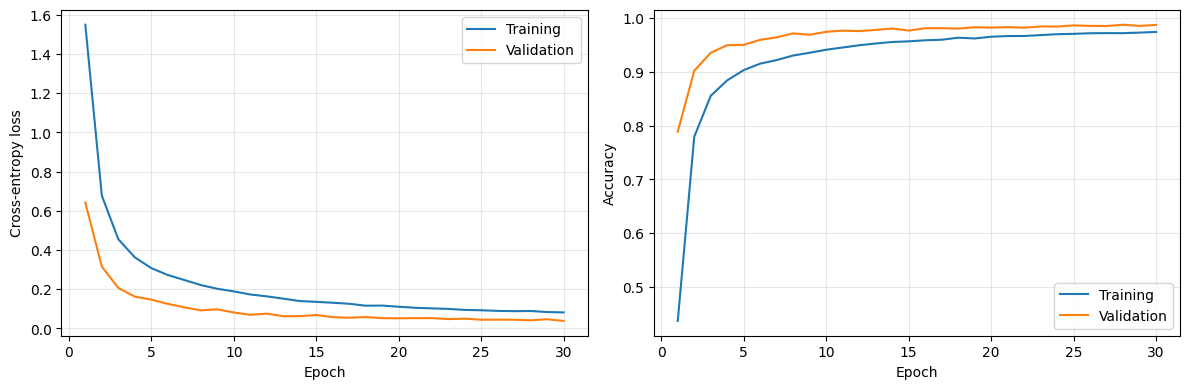

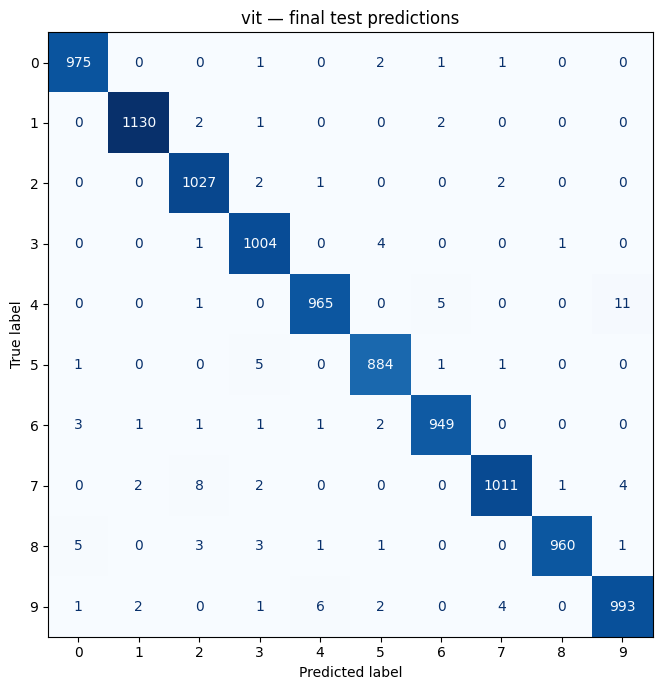

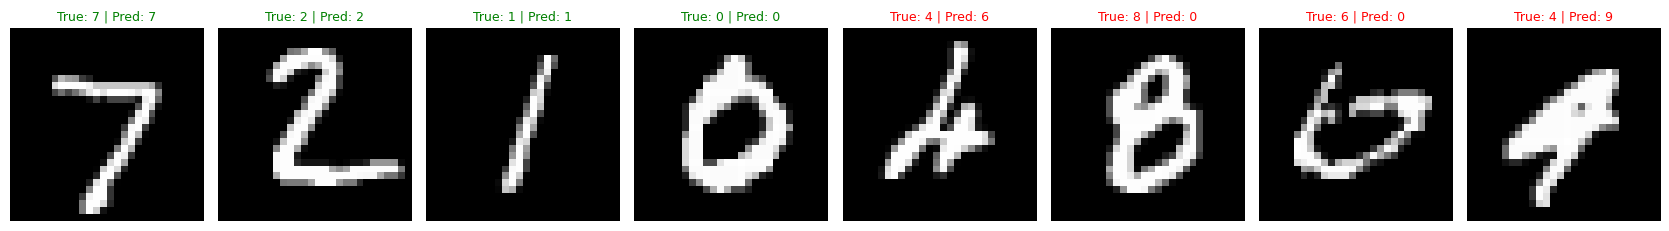

In [7]:
# Reload persisted results: rerunning this cell does not evaluate the model on the test set again.
history = json.loads((RUN_DIR / 'history.json').read_text())
with (RUN_DIR / 'predictions.csv').open() as file:
    rows = list(csv.DictReader(file))
targets = [int(row['true_digit']) for row in rows]
predictions = [int(row['predicted_digit']) for row in rows]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = [row['epoch'] for row in history]
for prefix, title in [('train', 'Training'), ('validation', 'Validation')]:
    axes[0].plot(epochs, [row[prefix + '_loss'] for row in history], label=title)
    axes[1].plot(epochs, [row[prefix + '_accuracy'] for row in history], label=title)
for ax, label in zip(axes, ['Cross-entropy loss', 'Accuracy']):
    ax.set_xlabel('Epoch'); ax.set_ylabel(label); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(targets, predictions, labels=list(range(10))), display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(MODEL_KEY + ' — final test predictions')
fig.tight_layout(); fig.savefig(RUN_DIR / 'confusion_matrix.png', dpi=160); plt.show()

error_indices = [i for i, (t, p) in enumerate(zip(targets, predictions)) if t != p]
example_indices = list(range(4)) + error_indices[:4]
raw_test = datasets.MNIST(LOCAL_DATA, train=False, download=False)
fig, axes = plt.subplots(1, len(example_indices), figsize=(2.1 * len(example_indices), 2.8), squeeze=False)
for ax, index in zip(axes.flat, example_indices):
    image, label = raw_test[index]
    predicted = predictions[index]
    ax.imshow(image, cmap='gray'); ax.axis('off')
    ax.set_title(f'True: {label} | Pred: {predicted}', color='green' if predicted == label else 'red', fontsize=9)
fig.tight_layout(); fig.savefig(RUN_DIR / 'prediction_examples.png', dpi=160); plt.show()


## 7. Update the cross-model comparison

    Run this cell again after completing another notebook. Missing experiments remain blank. Original Faster R-CNN scores are explicitly historical, with their original two-GPU configuration and known evaluation limitations; they are not outputs of corrected code.


In [8]:
model_order = ['cnn', 'faster_rcnn_original', 'vgg16', 'alexnet', 'vit']
comparison = []
for key in model_order:
    if key == 'faster_rcnn_original':
        comparison.append({'model': key, 'source': 'historical notebook output; not rerun',
                           'accuracy': 0.9922, 'f1_macro': 0.9921, 'test_loss': None,
                           'training_seconds': 79.9 * 60, 'gpu_count_used': 2, 'epochs_executed': 8,
                           'train_size': 59000, 'validation_size': 1000,
                           'note': 'From scratch, 64x64; validation BatchNorm updates and no-detection fallback limit reliability.'})
    else:
        path = PROJECT / 'runs' / key / 'metrics.json'
        if path.exists():
            comparison.append(json.loads(path.read_text()))
        else:
            comparison.append({'model': key, 'source': 'not yet evaluated'})
current_runs = [row for row in comparison if row.get('source') == 'new_colab_run']
if len({row['split_sha256'] for row in current_runs}) > 1:
    raise RuntimeError('Cannot combine runs with different dataset splits.')
if len({json.dumps(row['dataset_file_sha256'], sort_keys=True) for row in current_runs}) > 1:
    raise RuntimeError('Cannot combine runs whose Kaggle MNIST file fingerprints differ.')

def metric_text(value, percent=False):
    if value is None: return '—'
    return f'{value:.2%}' if percent else f'{value:.4f}'

lines = ['| Model | Test accuracy | Macro F1 | Test loss | Time (min) | GPUs | Epochs | Source |',
         '|---|---:|---:|---:|---:|---:|---:|---|']
for row in comparison:
    minutes = f'{row["training_seconds"] / 60:.2f}' if 'training_seconds' in row else '—'
    lines.append(f'| {row["model"]} | {metric_text(row.get("accuracy"), True)} | '
                 f'{metric_text(row.get("f1_macro"))} | {metric_text(row.get("test_loss"))} | '
                 f'{minutes} | {row.get("gpu_count_used", "—")} | {row.get("epochs_executed", "—")} | {row["source"]} |')
table = '\n'.join(lines)
print(table)
write_json(PROJECT / 'comparison.json', comparison)
(PROJECT / 'comparison.md').write_text(table + '\n\nHistorical Faster R-CNN results use a different protocol and retain known evaluation limitations. '
                                      'Times include validation and checkpoint writes for the new runs. '
                                      'Do not rank detection loss against classification cross-entropy.\n')
print('Saved:', PROJECT / 'comparison.md')


| Model | Test accuracy | Macro F1 | Test loss | Time (min) | GPUs | Epochs | Source |
|---|---:|---:|---:|---:|---:|---:|---|
| cnn | — | — | — | — | — | — | not yet evaluated |
| faster_rcnn_original | 99.22% | 0.9921 | — | 79.90 | 2 | 8 | historical notebook output; not rerun |
| vgg16 | — | — | — | — | — | — | not yet evaluated |
| alexnet | — | — | — | — | — | — | not yet evaluated |
| vit | 98.98% | 0.9897 | 0.0330 | 12.56 | 1 | 30 | new_colab_run |
Saved: /content/drive/MyDrive/Atelier2_MNIST/comparison.md


## 8. Interprétation des résultats

### Sélection du meilleur modèle et évolution de l’apprentissage

Le meilleur checkpoint a été sélectionné à l’**époque 30**, avec une perte de validation de **0,0385** et une accuracy de validation de **98,73 %**. D’après les courbes observées, les pertes d’entraînement et de validation diminuent globalement, sans divergence marquée suggérant un surapprentissage important.

L’entraînement atteint les **30 époques prévues** sans déclenchement de l’early stopping. Le meilleur checkpoint étant obtenu à la dernière époque, ces résultats ne permettent pas d’affirmer que le modèle a atteint son optimum. Un budget supplémentaire pourrait éventuellement améliorer la validation, mais cela resterait à vérifier dans une expérience distincte. Le jeu de test n’est pas utilisé pour sélectionner le checkpoint.

### Reconnaissance des chiffres et analyse des erreurs

Le Vision Transformer atteint une **accuracy de test de 98,98 %** et un **F1 macro de 0,9897**. Cela correspond à **9 898 prédictions correctes et 102 erreurs sur 10 000 images**. La proximité du F1 macro et de l’accuracy est cohérente avec une bonne performance moyenne sur les dix classes ; le rapport par classe permet d’en examiner les différences.

Les observations de la matrice de confusion et des exemples montrent notamment des chiffres **4 prédits comme des 9 ou des 6**, ainsi que des chiffres **8 ou 6 prédits comme des 0**. Certaines formes manuscrites peuvent rendre ces distinctions difficiles. Ces exemples illustrent les erreurs du modèle ; leur fréquence doit être déterminée à partir des effectifs de la matrice complète.

### Comparaison avec les autres architectures

| Modèle | Accuracy test | Temps d’entraînement | Matériel |
|---|---:|---:|---|
| CNN | 98,96 % | 7,19 minutes | 1 Tesla T4 |
| ViT | 98,98 % | 12,56 minutes | 1 Tesla T4 |
| AlexNet | 99,33 % | 11,80 minutes | 1 Tesla T4 |
| VGG16 | 99,40 % | 14,39 minutes | 1 Tesla T4 |
| Faster R-CNN | 99,22 % | 79,9 minutes | 2 Tesla T4 |

Le ViT obtient un score très proche de celui du CNN : l’écart est de **0,02 point de pourcentage**, soit seulement **deux erreurs de moins sur le test**. Son entraînement demande toutefois **5,37 minutes supplémentaires**, soit environ **75 % de temps en plus**. Cette différence minime d’accuracy ne permet pas d’établir une supériorité du ViT à partir d’une seule exécution.

AlexNet et VGG16 obtiennent de meilleurs scores dans les expériences réalisées. Ils bénéficient cependant de poids préentraînés, tandis que le ViT apprend tous ses paramètres à partir de zéro. Les architectures, les initialisations et les budgets d’entraînement diffèrent ; ces résultats décrivent donc les configurations testées plutôt qu’un classement général des familles de modèles.

La comparaison avec Faster R-CNN doit également tenir compte de son matériel, de son découpage des données et des limites identifiées dans sa procédure d’évaluation. Son accuracy caractérise la reconnaissance du chiffre sélectionné, sans mesurer directement la qualité de localisation.

### Portée et limites

Cette expérience montre qu’un ViT compact implémenté et entraîné à partir de zéro peut obtenir une bonne reconnaissance des chiffres de MNIST. Elle ne démontre pas pour autant un avantage général de l’auto-attention sur les convolutions, ni une convergence optimale à l’époque 30.

Une seule graine est utilisée pour chaque modèle. Plusieurs répétitions permettraient d’évaluer la variabilité des résultats et la stabilité de l’apprentissage. Un protocole contrôlant davantage les budgets de calcul et le préentraînement serait utile pour approfondir la comparaison.

### Synthèse personnelle

Ce travail m’a permis de construire un Vision Transformer en comprenant les étapes de découpage en patchs, de projection en tokens, d’ajout du token de classification et d’encodage positionnel sinusoïdal. J’ai également mis en œuvre l’auto-attention multi-têtes, les connexions résiduelles et les blocs de transformation sans charger de modèle préentraîné.

Avec une accuracy de **98,98 %**, cette architecture apprend efficacement la tâche étudiée. La comparaison m’a surtout montré qu’une approche différente ou plus complexe n’apporte pas nécessairement un gain important sur MNIST : dans cette exécution, le CNN compact atteint une accuracy presque identique en moins de temps. Le choix d’une architecture doit donc tenir compte des performances mesurées, du coût de calcul et de la nature du problème.
